In [1]:
# ==========================================
# CELL 1: IMPORT LIBRARIES
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

# Print TensorFlow version
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


In [2]:
# ==========================================
# CELL 2: LOAD CIFAR-10 DATASET
# ==========================================

# Load CIFAR-10 dataset
(x_train_cifar, y_train_cifar), (x_test_cifar, y_test_cifar) = \
    keras.datasets.cifar10.load_data()

# Print dataset information
print("CIFAR-10 Dataset")
print("----------------------------")

print("Training images:", x_train_cifar.shape)
print("Training labels:", y_train_cifar.shape)

print("Testing images:", x_test_cifar.shape)
print("Testing labels:", y_test_cifar.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1768s 10us/step
CIFAR-10 Dataset
----------------------------
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


In [7]:
# ==========================================
# CELL 3: CIFAR-10 CLASSES
# ==========================================

cifar_classes = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

print("Number of classes:", len(cifar_classes))

for i in range(len(cifar_classes)):
    print(i, "->", cifar_classes[i])

Number of classes: 10
0 -> Airplane
1 -> Automobile
2 -> Bird
3 -> Cat
4 -> Deer
5 -> Dog
6 -> Frog
7 -> Horse
8 -> Ship
9 -> Truck


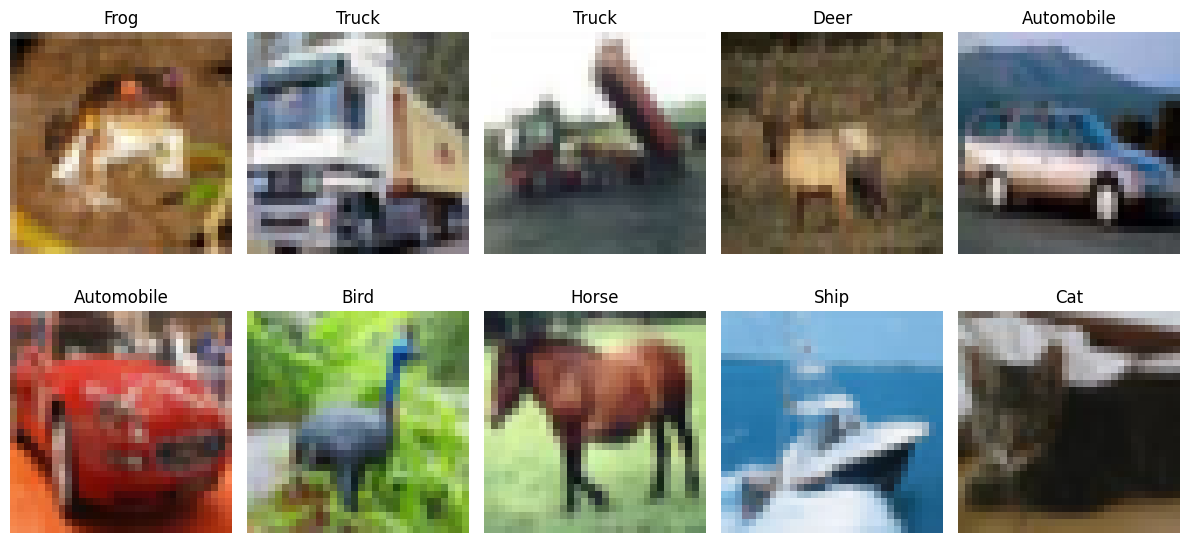

In [33]:
# ==========================================
# CELL 4: DISPLAY CIFAR-10 IMAGES
# ==========================================

plt.figure(figsize=(12, 6))

for i in range(10):

    # Create subplot
    plt.subplot(2, 5, i + 1)

    # Display image
    plt.imshow(x_train_cifar[i])

    # Get class number
    class_number = y_train_cifar[i][0]

    # Display class name
    plt.title(cifar_classes[class_number])

    # Remove axes
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
# ==========================================
# CELL 5: CIFAR-10 PIXEL INFORMATION
# ==========================================

print("Minimum pixel value:", x_train_cifar.min())
print("Maximum pixel value:", x_train_cifar.max())

print("Image height:", x_train_cifar.shape[1])
print("Image width:", x_train_cifar.shape[2])
print("Number of channels:", x_train_cifar.shape[3])

Minimum pixel value: 0
Maximum pixel value: 255
Image height: 32
Image width: 32
Number of channels: 3


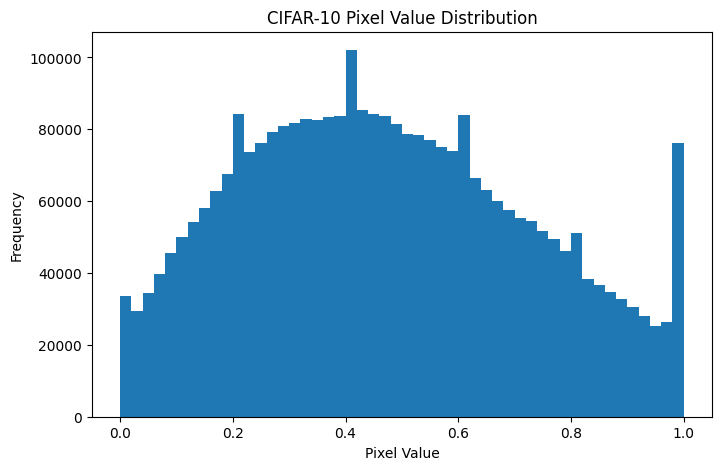

In [32]:
# ==========================================
# CELL 6: CIFAR-10 PIXEL DISTRIBUTION
# ==========================================

# Take first 1000 images
pixels = x_train_cifar[:1000].flatten()

# Plot histogram
plt.figure(figsize=(8, 5))

plt.hist(pixels, bins=50)

plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.title("CIFAR-10 Pixel Value Distribution")

plt.show()

In [11]:
# ==========================================
# CELL 7: LOAD FASHION-MNIST
# ==========================================

# Load Fashion-MNIST
(x_train_fashion, y_train_fashion), (x_test_fashion, y_test_fashion) = \
    keras.datasets.fashion_mnist.load_data()

# Print information
print("Fashion-MNIST Dataset")
print("----------------------------")

print("Training images:", x_train_fashion.shape)
print("Training labels:", y_train_fashion.shape)

print("Testing images:", x_test_fashion.shape)
print("Testing labels:", y_test_fashion.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Fashion-MNIST Dataset
----------------------------
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [12]:
# ==========================================
# CELL 8: FASHION-MNIST CLASSES
# ==========================================

fashion_classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Number of classes:", len(fashion_classes))

for i in range(len(fashion_classes)):
    print(i, "->", fashion_classes[i])

Number of classes: 10
0 -> T-shirt/top
1 -> Trouser
2 -> Pullover
3 -> Dress
4 -> Coat
5 -> Sandal
6 -> Shirt
7 -> Sneaker
8 -> Bag
9 -> Ankle boot


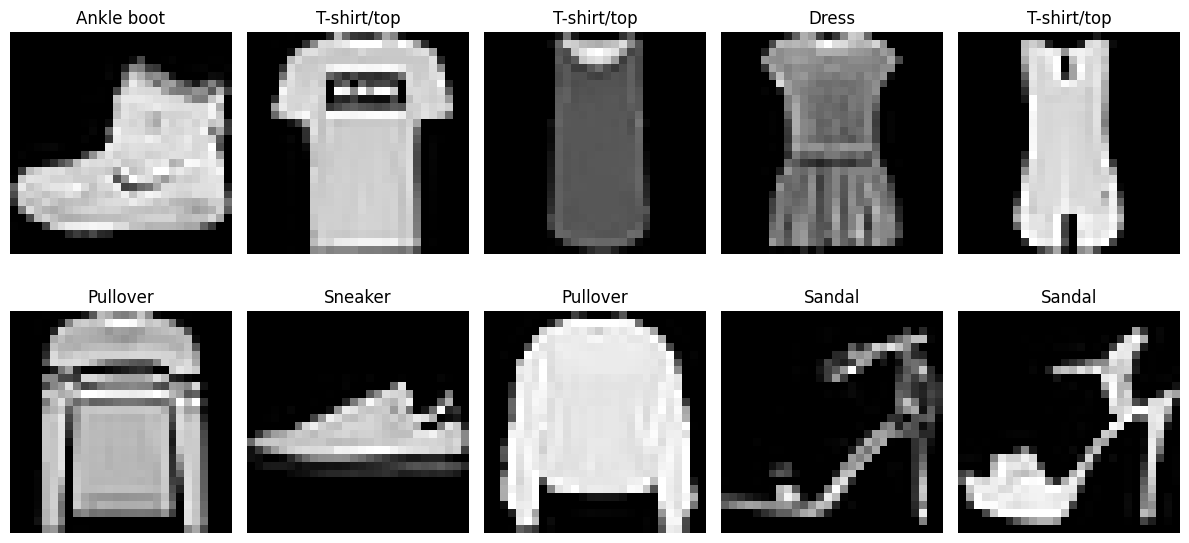

In [13]:
# ==========================================
# CELL 9: DISPLAY FASHION-MNIST IMAGES
# ==========================================

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    # Display grayscale image
    plt.imshow(x_train_fashion[i], cmap="gray")

    # Get class number
    class_number = y_train_fashion[i]

    # Display class name
    plt.title(fashion_classes[class_number])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# ==========================================
# CELL 10: FASHION-MNIST PIXEL INFORMATION
# ==========================================

print("Minimum pixel value:", x_train_fashion.min())
print("Maximum pixel value:", x_train_fashion.max())

print("Image height:", x_train_fashion.shape[1])
print("Image width:", x_train_fashion.shape[2])

Minimum pixel value: 0
Maximum pixel value: 255
Image height: 28
Image width: 28


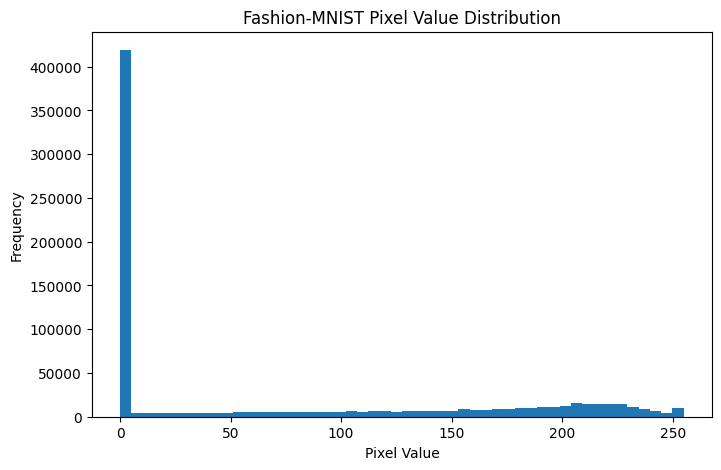

In [15]:
# ==========================================
# CELL 11: FASHION-MNIST PIXEL DISTRIBUTION
# ==========================================

pixels = x_train_fashion[:1000].flatten()

plt.figure(figsize=(8, 5))

plt.hist(pixels, bins=50)

plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.title("Fashion-MNIST Pixel Value Distribution")

plt.show()

In [16]:
# ==========================================
# CELL 12: PREPROCESS CIFAR-10
# ==========================================

# Convert pixels to float
x_train_cifar = x_train_cifar.astype("float32")
x_test_cifar = x_test_cifar.astype("float32")

# Normalize pixel values from 0-255 to 0-1
x_train_cifar = x_train_cifar / 255.0
x_test_cifar = x_test_cifar / 255.0

print("CIFAR-10 preprocessing completed.")

print("New minimum:", x_train_cifar.min())
print("New maximum:", x_train_cifar.max())

CIFAR-10 preprocessing completed.
New minimum: 0.0
New maximum: 1.0


In [17]:
# ==========================================
# CELL 13: PREPROCESS FASHION-MNIST
# ==========================================

# Convert to float
x_train_fashion = x_train_fashion.astype("float32")
x_test_fashion = x_test_fashion.astype("float32")

# Normalize pixels
x_train_fashion = x_train_fashion / 255.0
x_test_fashion = x_test_fashion / 255.0

# Add channel dimension
x_train_fashion = np.expand_dims(x_train_fashion, axis=-1)
x_test_fashion = np.expand_dims(x_test_fashion, axis=-1)

# Resize from 28x28 to 32x32
x_train_fashion = tf.image.resize(
    x_train_fashion,
    [32, 32]
)

x_test_fashion = tf.image.resize(
    x_test_fashion,
    [32, 32]
)

print("Fashion-MNIST preprocessing completed.")

print("Training shape:", x_train_fashion.shape)
print("Testing shape:", x_test_fashion.shape)

Fashion-MNIST preprocessing completed.
Training shape: (60000, 32, 32, 1)
Testing shape: (10000, 32, 32, 1)


In [18]:
# ==========================================
# CELL 14: BUILD AUTOENCODER
# ==========================================

def build_autoencoder(input_shape, latent_dim):

    # ======================================
    # ENCODER
    # ======================================

    # Input image
    input_image = keras.Input(shape=input_shape)

    # First convolution
    x = layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    )(input_image)

    # Reduce image size
    x = layers.MaxPooling2D((2, 2))(x)

    # Second convolution
    x = layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    )(x)

    # Reduce image size
    x = layers.MaxPooling2D((2, 2))(x)

    # Third convolution
    x = layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    )(x)

    # Reduce image size
    x = layers.MaxPooling2D((2, 2))(x)

    # Convert feature maps into one vector
    x = layers.Flatten()(x)

    # Create latent representation
    latent = layers.Dense(
        latent_dim,
        activation="relu"
    )(x)

    # ======================================
    # DECODER
    # ======================================

    # Convert latent vector back to feature maps
    x = layers.Dense(
        4 * 4 * 128,
        activation="relu"
    )(latent)

    # Reshape
    x = layers.Reshape((4, 4, 128))(x)

    # 4x4 -> 8x8
    x = layers.UpSampling2D((2, 2))(x)

    x = layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    )(x)

    # 8x8 -> 16x16
    x = layers.UpSampling2D((2, 2))(x)

    x = layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    )(x)

    # 16x16 -> 32x32
    x = layers.UpSampling2D((2, 2))(x)

    x = layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    )(x)

    # Final reconstructed image
    output_image = layers.Conv2D(
        input_shape[-1],
        (3, 3),
        activation="sigmoid",
        padding="same"
    )(x)

    # Create complete autoencoder
    autoencoder = keras.Model(
        input_image,
        output_image
    )

    return autoencoder

In [19]:
# ==========================================
# CELL 15: TEST AUTOENCODER
# ==========================================

# Create CIFAR-10 Autoencoder
model = build_autoencoder(
    input_shape=(32, 32, 3),
    latent_dim=16
)

# Compile model
model.compile(
    optimizer="adam",
    loss="mse"
)

# Display model architecture
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        32,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2048)           │        34,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 401,555 (1.53 MB)

 Trainable params: 401,555 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# ==========================================
# CELL 16: TRAIN CIFAR-10 AUTOENCODER
# ==========================================

history = model.fit(
    x_train_cifar,
    x_train_cifar,

    epochs=10,

    batch_size=128,

    validation_data=(
        x_test_cifar,
        x_test_cifar
    )
)

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - loss: 0.0288 - val_loss: 0.0222
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0216 - val_loss: 0.0212
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0212 - val_loss: 0.0211
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - loss: 0.0209 - val_loss: 0.0209
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0208 - val_loss: 0.0208
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - loss: 0.0207 - val_loss: 0.0207
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0206 - val_loss: 0.0208
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0205 - val_loss: 0.0208
Epoch 9/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0205 - val_loss: 0.0205
Epoch 10/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.0204 - val_loss: 0.0205


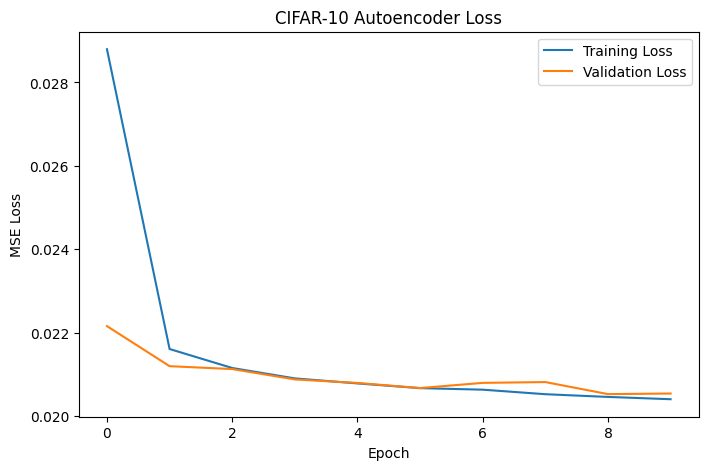

In [21]:
# ==========================================
# CELL 17: TRAINING LOSS
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title("CIFAR-10 Autoencoder Loss")

plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


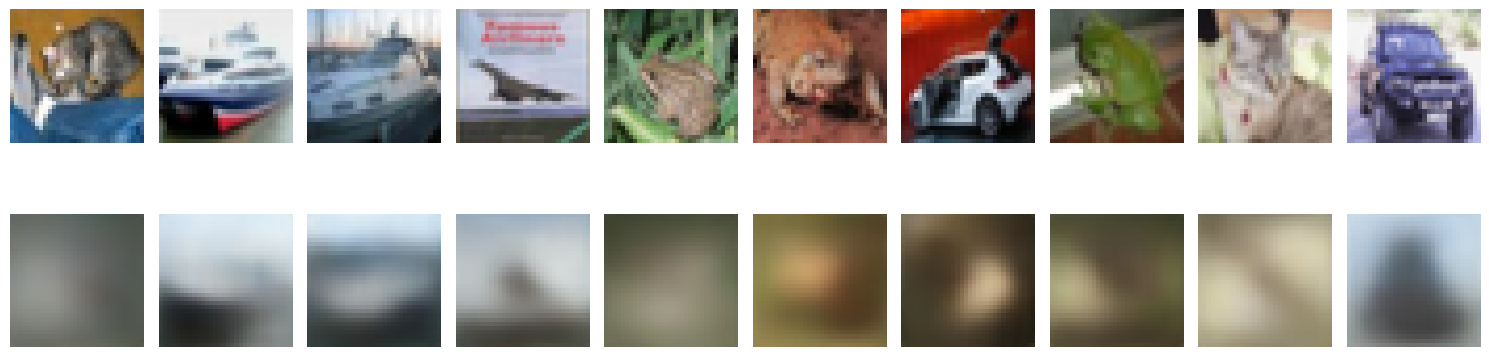

In [22]:
# ==========================================
# CELL 18: CIFAR-10 RECONSTRUCTION
# ==========================================

# Take 10 test images
original_images = x_test_cifar[:10]

# Reconstruct images
reconstructed_images = model.predict(
    original_images
)

# Display results
plt.figure(figsize=(15, 5))

for i in range(10):

    # Original
    plt.subplot(2, 10, i + 1)

    plt.imshow(original_images[i])

    plt.axis("off")

    # Reconstructed
    plt.subplot(2, 10, i + 11)

    plt.imshow(reconstructed_images[i])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
# ==========================================
# CELL 19: CIFAR-10 RECONSTRUCTION ERROR
# ==========================================

# Calculate Mean Squared Error
cifar_error = np.mean(
    np.square(
        x_test_cifar - model.predict(x_test_cifar)
    )
)

print("CIFAR-10 Reconstruction Error:", cifar_error)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
CIFAR-10 Reconstruction Error: 0.020538645


In [24]:
# ==========================================
# CELL 20: CIFAR-10 LATENT DIMENSION EXPERIMENT
# ==========================================

latent_dimensions = [16, 32, 64, 128]

cifar_results = {}

for latent_dim in latent_dimensions:

    print("\n================================")
    print("Latent Dimension:", latent_dim)
    print("================================")

    # Create model
    model = build_autoencoder(
        input_shape=(32, 32, 3),
        latent_dim=latent_dim
    )

    # Compile
    model.compile(
        optimizer="adam",
        loss="mse"
    )

    # Train
    model.fit(
        x_train_cifar,
        x_train_cifar,
        epochs=10,
        batch_size=128,
        validation_data=(
            x_test_cifar,
            x_test_cifar
        ),
        verbose=1
    )

    # Reconstruct test images
    reconstructed = model.predict(
        x_test_cifar,
        verbose=0
    )

    # Calculate reconstruction error
    error = np.mean(
        np.square(
            x_test_cifar - reconstructed
        )
    )

    # Store result
    cifar_results[latent_dim] = error

    print("Reconstruction Error:", error)


Latent Dimension: 16
Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 17s 31ms/step - loss: 0.0307 - val_loss: 0.0258
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.0256 - val_loss: 0.0253
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.0248 - val_loss: 0.0246
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - loss: 0.0244 - val_loss: 0.0244
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0243 - val_loss: 0.0243
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.0242 - val_loss: 0.0241
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.0241 - val_loss: 0.0243
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0235 - val_loss: 0.0229
Epoch 9/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.0227 - val_loss: 0.0228
Epoch 10/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0226 - val_loss: 0.0227
Reconstruction Error: 0.022743827

Latent Dimension: 32
Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 16s 30ms/s

In [25]:
# ==========================================
# CELL 21: CIFAR-10 RESULTS
# ==========================================

print("CIFAR-10 RESULTS")
print("==============================")

for latent_dim in latent_dimensions:

    print(
        "Latent Dimension:",
        latent_dim,
        "| Error:",
        cifar_results[latent_dim]
    )

CIFAR-10 RESULTS
Latent Dimension: 16 | Error: 0.022743827
Latent Dimension: 32 | Error: 0.015315595
Latent Dimension: 64 | Error: 0.010872371
Latent Dimension: 128 | Error: 0.008576092


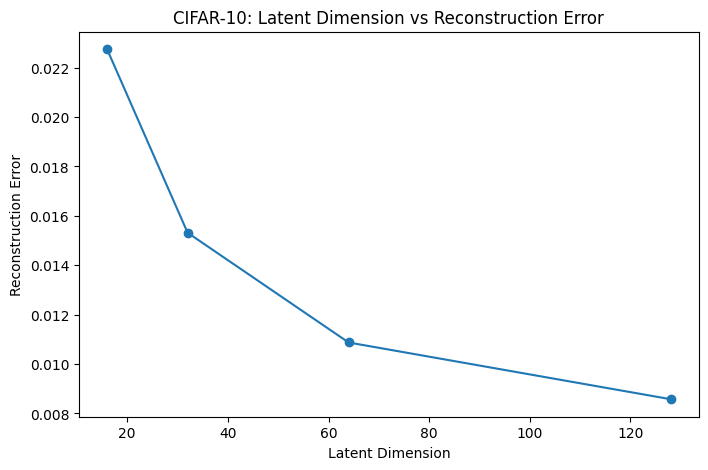

In [26]:
# ==========================================
# CELL 22: CIFAR-10 COMPARISON
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    list(cifar_results.keys()),
    list(cifar_results.values()),
    marker="o"
)

plt.xlabel("Latent Dimension")
plt.ylabel("Reconstruction Error")

plt.title(
    "CIFAR-10: Latent Dimension vs Reconstruction Error"
)

plt.show()

In [27]:
# ==========================================
# CELL 23: FASHION-MNIST EXPERIMENT
# ==========================================

fashion_results = {}

for latent_dim in latent_dimensions:

    print("\n================================")
    print("Latent Dimension:", latent_dim)
    print("================================")

    # Create model
    model = build_autoencoder(
        input_shape=(32, 32, 1),
        latent_dim=latent_dim
    )

    # Compile
    model.compile(
        optimizer="adam",
        loss="mse"
    )

    # Train
    model.fit(
        x_train_fashion,
        x_train_fashion,
        epochs=10,
        batch_size=128,
        validation_data=(
            x_test_fashion,
            x_test_fashion
        ),
        verbose=1
    )

    # Reconstruct test images
    reconstructed = model.predict(
        x_test_fashion,
        verbose=0
    )

    # Calculate reconstruction error
    error = np.mean(
        np.square(
            x_test_fashion - reconstructed
        )
    )

    # Store result
    fashion_results[latent_dim] = error

    print("Reconstruction Error:", error)


Latent Dimension: 16
Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - loss: 0.0209 - val_loss: 0.0111
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - loss: 0.0096 - val_loss: 0.0085
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0079 - val_loss: 0.0073
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0071 - val_loss: 0.0069
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0066 - val_loss: 0.0066
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.0064 - val_loss: 0.0062
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.0062 - val_loss: 0.0062
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.0060 - val_loss: 0.0061
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.0059 - val_loss: 0.0059
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.0058 - val_loss: 0.0058
Reconstruction Error: 0.0057942187

Latent Dimension: 32
Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/

In [28]:
# ==========================================
# CELL 24: FASHION-MNIST RESULTS
# ==========================================

print("FASHION-MNIST RESULTS")
print("==============================")

for latent_dim in latent_dimensions:

    print(
        "Latent Dimension:",
        latent_dim,
        "| Error:",
        fashion_results[latent_dim]
    )

FASHION-MNIST RESULTS
Latent Dimension: 16 | Error: 0.0057942187
Latent Dimension: 32 | Error: 0.0051938198
Latent Dimension: 64 | Error: 0.004263725
Latent Dimension: 128 | Error: 0.0038494903


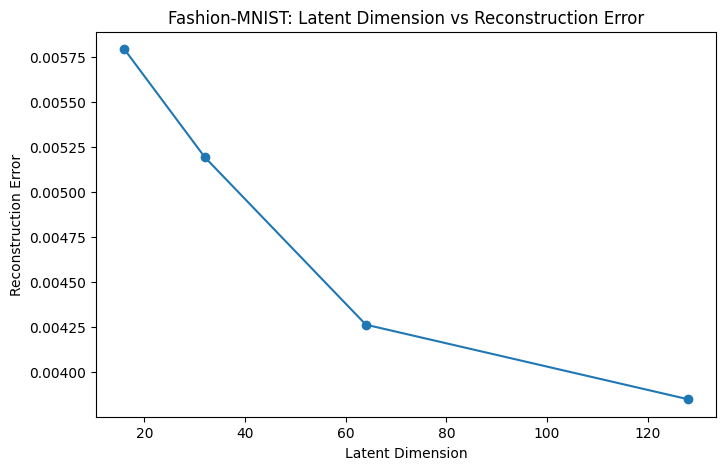

In [29]:
# ==========================================
# CELL 25: FASHION-MNIST COMPARISON
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    list(fashion_results.keys()),
    list(fashion_results.values()),
    marker="o"
)

plt.xlabel("Latent Dimension")
plt.ylabel("Reconstruction Error")

plt.title(
    "Fashion-MNIST: Latent Dimension vs Reconstruction Error"
)

plt.show()

In [30]:
# ==========================================
# CELL 26: FINAL COMPARISON
# ==========================================

print(
    "Latent Dimension | CIFAR-10 Error | Fashion-MNIST Error"
)
print("-" * 60)

for latent_dim in latent_dimensions:

    print(
        f"{latent_dim:^16} | "
        f"{cifar_results[latent_dim]:^15.6f} | "
        f"{fashion_results[latent_dim]:^20.6f}"
    )

Latent Dimension | CIFAR-10 Error | Fashion-MNIST Error
------------------------------------------------------------
       16        |    0.022744     |       0.005794      
       32        |    0.015316     |       0.005194      
       64        |    0.010872     |       0.004264      
      128        |    0.008576     |       0.003849      
